# 08 · Gold standard zespołu – ocena trzech modeli (tylko `hate`)

**Gold standard:** `data/annotation/gold/gold.csv` – 600 komentarzy (po 200 z Wykopu, Bluesky i YouTube), wynik rundy
`gold_v1` zespołu (`scripts/gold_build.py`: etykiety dwóch anotatorów LLM + rozstrzygnięcia). Oceniamy tylko etykietę `hate`
(`hate_migrants` nie jest oceniana – żaden z modeli nie rozróżnia adresata).

**Modele** – dokładnie ten sam przebieg co w notebookach 04 / 05 / 07:

| Model | folder wyników | notebook |
|---|---|---|
| HerBERT-large, mowa nienawiści (PolEval 2019) | `herbert/` | 04 |
| Polbert, cyberbullying (PolEval 2019) | `polbert/` | 05 |
| Polish RoBERTa-base-v2 douczony na BAN-PL | `roberta_banpl/` | 06 → 07 |

Każdy model ocenia wszystkie 600 tekstów (tekst z `clean/` po `comment_id`, czyli ten sam, który widzi przy predykcji;
2 komentarze bez `clean/` – tekst z gold standardu). Porównujemy trzy warianty etykiety:

- **słownik + model** (`hate_final`) – pipeline z notebooków 04–07: obelga ze słownika (`hate_auto = 1`) → hejt, reszta → model; **główny wariant**,
- **sam model** (`prob_hate_max ≥ 0.5`),
- **sam słownik** – punkt odniesienia.

Wyniki: ogółem i osobno dla każdej platformy, z 95% przedziałami ufności (bootstrap). Najlepszy model (F1 wariantu
„słownik + model”, ogółem) trafia do `reports/gold_model_eval/best_model.json` – czytają go notebooki analiz
(`notebooks/hate_analysis_models/`). Pliki zespołu w `data/annotation/` nie są zmieniane.

In [1]:
# ── KONFIGURACJA ──────────────────────────────────────────────────────────────
GOLD = "data/annotation/gold/gold.csv"
MODELS = {   # nazwa -> (folder wyników, źródło modelu, indeks klasy hate)
    "HerBERT-HS": ("herbert", "dkleczek/Polish-Hate-Speech-Detection-Herbert-Large", 1),
    "Polbert-CB": ("polbert", "ptaszynski/bert-base-polish-cyberbullying", 1),
    "RoBERTa-BAN-PL": ("roberta_banpl", "models/polish-roberta-base-v2-banpl", 1),
}
THRESHOLD = 0.5
MAX_LENGTH = 512
SELECT_VARIANT = "słownik + model"   # wariant, wg którego wybieramy najlepszy model
SELECT_BY = "f1"
N_BOOT = 2000
SEED = 2026
OUT_DIR = "reports/gold_model_eval"

In [2]:
import json, os, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.classifier.hate_models import Predictor, flag_frame, read_csv
from src.classifier.banpl import Unmasker, model_input

OUT = ROOT / OUT_DIR
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 180)

env = {}
if (ROOT / ".env").exists():
    for line in (ROOT / ".env").read_text(encoding="utf-8").splitlines():
        if "=" in line and not line.strip().startswith("#"):
            k, v = line.split("=", 1)
            env[k.strip()] = v.strip().strip('"').strip("'")
HF_TOKEN = env.get("TOKEN") or env.get("HF_TOKEN") or os.environ.get("HF_TOKEN")

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

gold = read_csv(ROOT / GOLD)
assert (gold["hate"].isin(["0", "1"])).all(), "w gold.csv są puste etykiety hate"
gold["gold"] = gold["hate"].astype(int)
print(f"gold: {len(gold)} komentarzy | hate=1: {gold['gold'].sum()} ({gold['gold'].mean():.1%}) | device: {DEVICE}")
display(gold.groupby("platform").agg(n=("gold", "size"), hate=("gold", "sum"), udzial_hate=("gold", "mean")).round(3))
display(gold["label_source"].value_counts().rename("źródło etykiety w gold.csv").to_frame())

gold: 600 komentarzy | hate=1: 337 (56.2%) | device: mps


/Users/gosia/Desktop/SZT_SEM_2/AMC/AMC_FINAL/Social_Media_Hate_Speech/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


,n,hate,udzial_hate
platform,,,
bluesky,200,69,0.345
wykop,200,125,0.625
youtube,200,143,0.715


,źródło etykiety w gold.csv
label_source,
unanimous,296
unanimous_uncertain,130
adjudicated,127
checked,47


## 1. Tekst wejściowy i słownik obelg

In [3]:
# tekst = clean/comments.csv (to samo, co widzi model przy predykcji); brak clean -> tekst z gold.csv
texts, source = [], []
cache = {}
for _, r in gold.iterrows():
    key = (r["platform"], r["event_folder"])
    if key not in cache:
        p = ROOT / "data" / "interim" / r["platform"] / r["event_folder"] / "clean" / "comments.csv"
        cache[key] = (read_csv(p).drop_duplicates("comment_id").set_index("comment_id")["text"]
                      if p.exists() else pd.Series(dtype=str))
    t = cache[key].get(r["comment_id"])
    texts.append(t if isinstance(t, str) and t.strip() else r["text"])
    source.append("clean" if isinstance(t, str) and t.strip() else "gold.csv")
gold["model_text"], gold["text_source"] = texts, source
print(gold["text_source"].value_counts().to_dict())

# słownik: ta sama funkcja co etap DVC slurs_* (scripts/preprocess_slurs.flag_frame)
lex = flag_frame(gold[["comment_id", "model_text"]].rename(columns={"model_text": "text"}), "comment_id")
gold["hate_auto"] = lex["hate_auto"].astype(int).values
gold["slurs"] = lex["slurs"].values
print(f"słownik (hate_auto=1): {gold['hate_auto'].sum()} komentarzy; z nich gold hate=1: "
      f"{gold.loc[gold['hate_auto'] == 1, 'gold'].mean():.1%}")

{'clean': 598, 'gold.csv': 2}
słownik (hate_auto=1): 57 komentarzy; z nich gold hate=1: 94.7%


## 2. Predykcje trzech modeli

In [4]:
probs, skipped = {}, {}
for name, (folder, source, idx) in MODELS.items():
    prep, model_id, token = None, source, HF_TOKEN
    if folder == "roberta_banpl":
        mdir = ROOT / source
        if not (mdir / "config.json").exists():
            skipped[name] = "brak modelu – odpal notebook 06"
            continue
        meta = json.loads((mdir / "training_meta.json").read_text(encoding="utf-8"))
        if meta.get("smoke_test"):
            skipped[name] = "model z SMOKE_TEST – wytrenuj pełny model w notebooku 06"
            continue
        unm = Unmasker(mdir / "polish_vulgarisms.txt")
        prep = lambda t, unm=unm, deb=meta.get("debias", True): model_input(t, unm, debias=deb)
        model_id, token = str(mdir), None
    t0 = time.time()
    pr = Predictor(model_id, DEVICE, prep=prep, max_length=MAX_LENGTH, hate_label_index=idx, token=token)
    _, pmax, _, _ = pr.predict(gold["model_text"].tolist())
    probs[name] = pmax
    gold[f"prob_{folder}"] = pmax.round(5)
    print(f"{name}: {time.time() - t0:.0f}s ({pr.precision})")
    del pr
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
for k, v in skipped.items():
    print(f"POMINIĘTY {k}: {v}")

/Users/gosia/Desktop/SZT_SEM_2/AMC/AMC_FINAL/Social_Media_Hate_Speech/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HerBERT-HS: 8s (float16)
Polbert-CB: 3s (float16)
RoBERTa-BAN-PL: 3s (float16)


## 3. Metryki (klasa pozytywna: `hate = 1`)

In [5]:
def scores(y, p, prob=None):
    y, p = np.asarray(y, int), np.asarray(p, int)
    tp, fp = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum())
    fn, tn = int(((p == 0) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    npv = tn / (tn + fn) if tn + fn else 0.0
    f1n = 2 * npv * spec / (npv + spec) if npv + spec else 0.0
    den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    out = {"accuracy": (tp + tn) / len(y), "precision": prec, "recall": rec, "f1": f1, "specificity": spec,
           "macro_f1": (f1 + f1n) / 2, "mcc": (tp * tn - fp * fn) / den if den else 0.0,
           "tp": tp, "fp": fp, "fn": fn, "tn": tn}
    if prob is not None:
        pos, neg = np.asarray(prob)[y == 1], np.asarray(prob)[y == 0]
        out["roc_auc"] = float(((pos[:, None] > neg[None, :]).sum() + 0.5 * (pos[:, None] == neg[None, :]).sum())
                               / (len(pos) * len(neg))) if len(pos) and len(neg) else np.nan
    return out

def boot_ci(y, p, metric, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y, int), np.asarray(p, int)
    vals = [scores(y[i], p[i])[metric] for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.quantile(vals, [0.025, 0.975]).round(3).tolist()

def variants(name):
    folder = MODELS[name][0]
    model = (gold[f"prob_{folder}"] >= THRESHOLD).astype(int)
    return {"słownik + model": np.where(gold["hate_auto"] == 1, 1, model), "sam model": model.values}

rows = []
scopes = [("ogółem", gold.index)] + [(f"{p}", g.index) for p, g in gold.groupby("platform")]
for scope, idx in scopes:
    y = gold.loc[idx, "gold"].values
    rows.append({"model": "sam słownik", "wariant": "sam słownik", "zakres": scope, "n": len(idx),
                 **scores(y, gold.loc[idx, "hate_auto"].values), "f1_ci95": boot_ci(y, gold.loc[idx, "hate_auto"], "f1")})
    for name in probs:
        for vname, pred in variants(name).items():
            p = np.asarray(pred)[gold.index.get_indexer(idx)]
            s = scores(y, p, gold.loc[idx, f"prob_{MODELS[name][0]}"].values)
            rows.append({"model": name, "wariant": vname, "zakres": scope, "n": len(idx), **s,
                         "f1_ci95": boot_ci(y, p, "f1"), "udzial_pred_hate": round(float(p.mean()), 3)})
metrics = pd.DataFrame(rows)
num = ["accuracy", "precision", "recall", "f1", "specificity", "macro_f1", "mcc", "roc_auc"]
metrics[num] = metrics[num].astype(float).round(3)
metrics.to_csv(OUT / "model_metrics.csv", index=False, encoding="utf-8-sig")

cols = ["model", "wariant", "n", "accuracy", "precision", "recall", "f1", "f1_ci95", "mcc", "roc_auc", "udzial_pred_hate"]
for scope, _ in scopes:
    print(f"\n=== {scope} (gold hate=1: {gold.loc[gold.index if scope == 'ogółem' else gold['platform'] == scope, 'gold'].mean():.1%}) ===")
    display(metrics[metrics["zakres"] == scope][cols].set_index(["model", "wariant"]))
print("ROC-AUC liczony z prob_hate_max modelu (niezależny od progu). Zapisano:", (OUT / "model_metrics.csv").relative_to(ROOT))


=== ogółem (gold hate=1: 56.2%) ===


n  accuracy  precision  recall     f1  \
model          wariant                                                    
sam słownik    sam słownik      600     0.523      0.947   0.160  0.274   
HerBERT-HS     słownik + model  600     0.772      0.805   0.783  0.794   
               sam model        600     0.762      0.805   0.760  0.782   
Polbert-CB     słownik + model  600     0.687      0.874   0.516  0.649   
               sam model        600     0.632      0.858   0.412  0.557   
RoBERTa-BAN-PL słownik + model  600     0.598      0.843   0.350  0.495   
               sam model        600     0.528      0.793   0.217  0.340   

                                       f1_ci95    mcc  roc_auc  \
model          wariant                                           
sam słownik    sam słownik      [0.214, 0.333]  0.252      NaN   
HerBERT-HS     słownik + model  [0.758, 0.826]  0.538    0.827   
               sam model        [0.745, 0.815]  0.521    0.827   
Polbert-CB     słownik + model  [0.598, 0.696]  0.444    0.758   
               sam model        [0.504, 0.607]  0.363    0.758   
RoBERTa-BAN-PL słownik + model  [0.435, 0.549]  0.313    0.681   
               sam model        [0.281, 0.399]  0.199    0.681   

                                udzial_pred_hate  
model          wariant                            
sam słownik    sam słownik                   NaN  
HerBERT-HS     słownik + model             0.547  
               sam model                   0.530  
Polbert-CB     słownik + model             0.332  
               sam model                   0.270  
RoBERTa-BAN-PL słownik + model             0.233  
               sam model                   0.153


=== bluesky (gold hate=1: 34.5%) ===


n  accuracy  precision  recall     f1  \
model          wariant                                                    
sam słownik    sam słownik      200     0.675      0.833   0.072  0.133   
HerBERT-HS     słownik + model  200     0.745      0.622   0.667  0.643   
               sam model        200     0.745      0.622   0.667  0.643   
Polbert-CB     słownik + model  200     0.785      0.750   0.565  0.645   
               sam model        200     0.775      0.740   0.536  0.622   
RoBERTa-BAN-PL słownik + model  200     0.715      0.667   0.348  0.457   
               sam model        200     0.700      0.645   0.290  0.400   

                                       f1_ci95    mcc  roc_auc  \
model          wariant                                           
sam słownik    sam słownik      [0.031, 0.247]  0.181      NaN   
HerBERT-HS     słownik + model  [0.547, 0.729]  0.446    0.828   
               sam model        [0.547, 0.729]  0.446    0.828   
Polbert-CB     słownik + model  [0.544, 0.738]  0.505    0.818   
               sam model        [0.517, 0.719]  0.480    0.818   
RoBERTa-BAN-PL słownik + model  [0.337, 0.569]  0.317    0.660   
               sam model        [0.273, 0.519]  0.270    0.660   

                                udzial_pred_hate  
model          wariant                            
sam słownik    sam słownik                   NaN  
HerBERT-HS     słownik + model             0.370  
               sam model                   0.370  
Polbert-CB     słownik + model             0.260  
               sam model                   0.250  
RoBERTa-BAN-PL słownik + model             0.180  
               sam model                   0.155


=== wykop (gold hate=1: 62.5%) ===


n  accuracy  precision  recall     f1  \
model          wariant                                                    
sam słownik    sam słownik      200     0.495      0.962   0.200  0.331   
HerBERT-HS     słownik + model  200     0.795      0.856   0.808  0.831   
               sam model        200     0.780      0.858   0.776  0.815   
Polbert-CB     słownik + model  200     0.650      0.951   0.464  0.624   
               sam model        200     0.560      0.951   0.312  0.470   
RoBERTa-BAN-PL słownik + model  200     0.585      0.920   0.368  0.526   
               sam model        200     0.485      0.893   0.200  0.327   

                                       f1_ci95    mcc  roc_auc  \
model          wariant                                           
sam słownik    sam słownik      [0.233, 0.426]  0.269      NaN   
HerBERT-HS     słownik + model  [0.778, 0.879]  0.572    0.842   
               sam model        [0.757, 0.864]  0.549    0.842   
Polbert-CB     słownik + model  [0.538, 0.702]  0.446    0.753   
               sam model        [0.371, 0.564]  0.342    0.753   
RoBERTa-BAN-PL słownik + model  [0.426, 0.612]  0.352    0.708   
               sam model        [0.227, 0.418]  0.223    0.708   

                                udzial_pred_hate  
model          wariant                            
sam słownik    sam słownik                   NaN  
HerBERT-HS     słownik + model             0.590  
               sam model                   0.565  
Polbert-CB     słownik + model             0.305  
               sam model                   0.205  
RoBERTa-BAN-PL słownik + model             0.250  
               sam model                   0.140


=== youtube (gold hate=1: 71.5%) ===


n  accuracy  precision  recall     f1  \
model          wariant                                                    
sam słownik    sam słownik      200     0.400      0.960   0.168  0.286   
HerBERT-HS     słownik + model  200     0.775      0.860   0.818  0.839   
               sam model        200     0.760      0.863   0.790  0.825   
Polbert-CB     słownik + model  200     0.625      0.895   0.538  0.672   
               sam model        200     0.560      0.887   0.441  0.589   
RoBERTa-BAN-PL słownik + model  200     0.495      0.889   0.336  0.487   
               sam model        200     0.400      0.848   0.196  0.318   

                                       f1_ci95    mcc  roc_auc  \
model          wariant                                           
sam słownik    sam słownik      [0.195, 0.374]  0.205      NaN   
HerBERT-HS     słownik + model  [0.791, 0.883]  0.469    0.776   
               sam model        [0.773, 0.871]  0.451    0.776   
Polbert-CB     słownik + model  [0.596, 0.739]  0.347    0.695   
               sam model        [0.507, 0.664]  0.283    0.695   
RoBERTa-BAN-PL słownik + model    [0.4, 0.571]  0.234    0.688   
               sam model         [0.23, 0.407]  0.131    0.688   

                                udzial_pred_hate  
model          wariant                            
sam słownik    sam słownik                   NaN  
HerBERT-HS     słownik + model             0.680  
               sam model                   0.655  
Polbert-CB     słownik + model             0.430  
               sam model                   0.355  
RoBERTa-BAN-PL słownik + model             0.270  
               sam model                   0.165

ROC-AUC liczony z prob_hate_max modelu (niezależny od progu). Zapisano: reports/gold_model_eval/model_metrics.csv


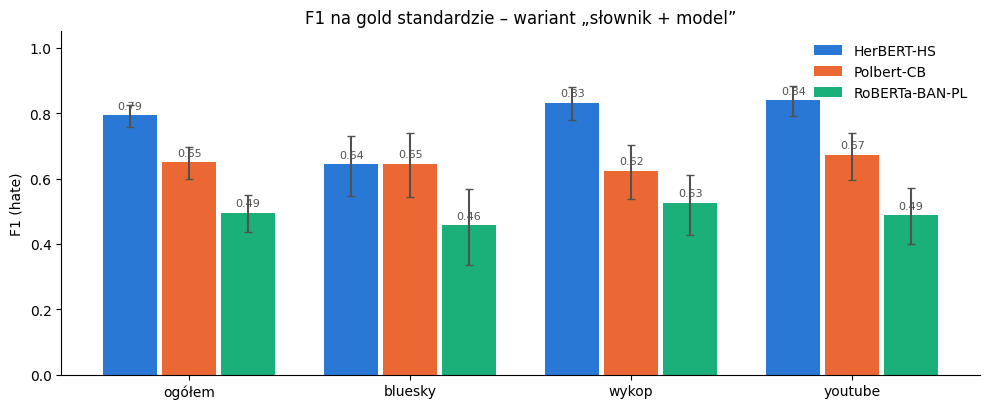

In [6]:
# F1 wariantu "słownik + model" – ogółem i per platforma (kreski = 95% CI)
m = metrics[(metrics["wariant"] == SELECT_VARIANT)]
scope_order = [s for s, _ in scopes]
names = list(probs)
fig, ax = plt.subplots(figsize=(10, 4.2))
w = 0.8 / max(len(names), 1)
colors = ["#2a78d6", "#eb6834", "#1baf7a"]
for i, name in enumerate(names):
    e = m[m["model"] == name].set_index("zakres").reindex(scope_order)
    x = np.arange(len(scope_order)) + (i - (len(names) - 1) / 2) * w
    lo = e["f1"] - e["f1_ci95"].map(lambda v: v[0]); hi = e["f1_ci95"].map(lambda v: v[1]) - e["f1"]
    ax.bar(x, e["f1"], w * 0.92, color=colors[i % 3], label=name, yerr=[lo, hi], capsize=3, ecolor="#52514e")
    for xi, v in zip(x, e["f1"]):
        ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(range(len(scope_order)), scope_order)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1 (hate)")
ax.set_title(f"F1 na gold standardzie – wariant „{SELECT_VARIANT}”")
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

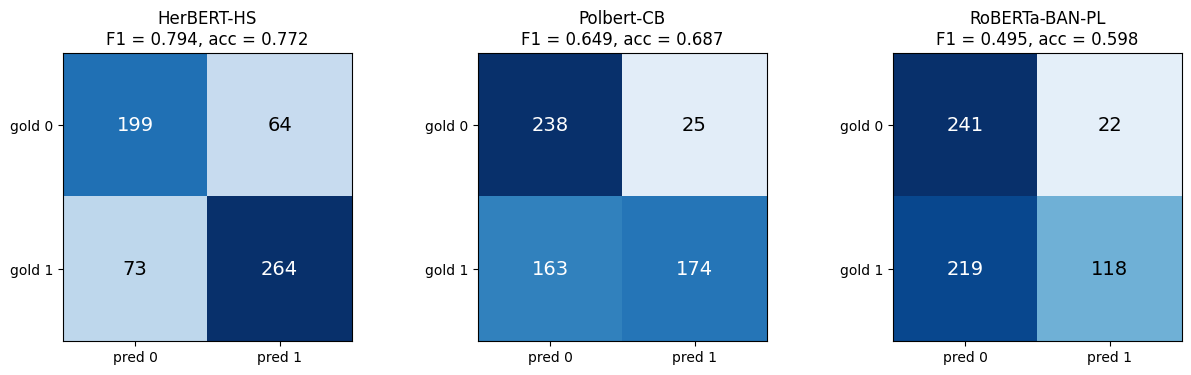

In [7]:
# macierze pomyłek – wariant "słownik + model", ogółem
fig, axes = plt.subplots(1, len(probs), figsize=(4.2 * len(probs), 3.8), squeeze=False)
for ax, name in zip(axes[0], probs):
    p = variants(name)[SELECT_VARIANT]
    s = scores(gold["gold"], p)
    mat = np.array([[s["tn"], s["fp"]], [s["fn"], s["tp"]]])
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=mat.max())
    for (i, j), v in np.ndenumerate(mat):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=14, color="white" if v > mat.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred 0", "pred 1"]); ax.set_yticks([0, 1], ["gold 0", "gold 1"])
    ax.set_title(f"{name}\nF1 = {s['f1']:.3f}, acc = {s['accuracy']:.3f}")
plt.tight_layout(); plt.show()

## 4. Najlepszy model

In [8]:
sel = metrics[(metrics["zakres"] == "ogółem") & (metrics["wariant"] == SELECT_VARIANT) & (metrics["model"].isin(probs))]
best = sel.sort_values([SELECT_BY, "mcc"], ascending=False).iloc[0]
info = {"model": best["model"], "folder": MODELS[best["model"]][0], "variant": SELECT_VARIANT,
        "label_column": "hate_final" if SELECT_VARIANT == "słownik + model" else "hate_pred_max",
        "selected_by": SELECT_BY, "f1": float(best["f1"]), "f1_ci95": best["f1_ci95"], "accuracy": float(best["accuracy"]),
        "mcc": float(best["mcc"]), "models_compared": list(probs), "gold": GOLD, "n": int(len(gold))}
(OUT / "best_model.json").write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Najlepszy ({SELECT_VARIANT}, wg {SELECT_BY}): {best['model']} – F1 {best['f1']:.3f} {best['f1_ci95']}, "
      f"accuracy {best['accuracy']:.3f}, MCC {best['mcc']:.3f}")
display(sel[["model", "f1", "f1_ci95", "accuracy", "precision", "recall", "mcc", "roc_auc"]].set_index("model"))
if skipped:
    print("UWAGA – porównanie bez:", ", ".join(skipped), "(po notebooku 06 odpal ten notebook ponownie)")
print("zapisano:", (OUT / "best_model.json").relative_to(ROOT))

Najlepszy (słownik + model, wg f1): HerBERT-HS – F1 0.794 [0.758, 0.826], accuracy 0.772, MCC 0.538


,f1,f1_ci95,accuracy,precision,recall,mcc,roc_auc
model,,,,,,,
HerBERT-HS,0.794,"[0.758, 0.826]",0.772,0.805,0.783,0.538,0.827
Polbert-CB,0.649,"[0.598, 0.696]",0.687,0.874,0.516,0.444,0.758
RoBERTa-BAN-PL,0.495,"[0.435, 0.549]",0.598,0.843,0.350,0.313,0.681


zapisano: reports/gold_model_eval/best_model.json


In [9]:
# predykcje per komentarz + błędy najlepszego modelu (do analizy jakościowej)
for name in probs:
    gold[f"pred_{MODELS[name][0]}"] = variants(name)[SELECT_VARIANT]
keep = ["item_id", "platform", "event_folder", "comment_id", "pool", "gold", "hate_auto", "slurs"] + \
       [c for c in gold.columns if c.startswith(("prob_", "pred_"))] + ["model_text"]
gold[keep].to_csv(OUT / "gold_predictions.csv", index=False, encoding="utf-8-sig")

col = f"pred_{info['folder']}"
err = gold[gold[col] != gold["gold"]].assign(błąd=lambda d: np.where(d[col] == 1, "FP (model: hejt)", "FN (model: brak)"))
print(f"{info['model']}: {len(err)} błędów na {len(gold)}")
display(err.groupby(["platform", "błąd"]).size().unstack(fill_value=0))
display(err.sort_values(["błąd", f"prob_{info['folder']}"])[["item_id", "platform", "błąd", f"prob_{info['folder']}", "model_text"]].head(40))

HerBERT-HS: 137 błędów na 600


błąd,FN (model: brak),FP (model: hejt)
platform,,
bluesky,23,28
wykop,24,17
youtube,26,19


,item_id,platform,błąd,prob_herbert,model_text
467,P0468,youtube,FN (model: brak),0.01758,W Polsce nie ma problemu ( na razie ) bo nie ma duzo tej holoty.
206,P0207,bluesky,FN (model: brak),0.02311,Na front wschodni w samych onucach
438,P0439,youtube,FN (model: brak),0.03168,"Ukraińcy muszą płacić za.służbę zdrowia, Gabinety prywatne odłączone."
565,P0566,youtube,FN (model: brak),0.03234,"Ale to głąb , Ukraińcy to nie emigracja zarobkowa. A jak nie jesteście w temacie to polecam jakie prywatne statki i z jakich krajów są właściciele... Śmiech"
532,P0533,youtube,FN (model: brak),0.03768,Brać tych przybyłych inżynierów i lekarzy.
542,P0543,youtube,FN (model: brak),0.04369,"Tak, na pewno, po 2-tygodniowym pobycie na wakacjach ktoś przywiezie butelkę zakupioną na lotnisku, żeby oddać ją do butelkomatu na lotnisku.\nAgro-pelet to w Afryce dawno używ..."
72,P0073,wykop,FN (model: brak),0.04964,"kacapia może też zaproponować diamenty z planety układu pulsara PSR J , albo nawet te z Merkurego. Propozycja będzie równie możliwa do zrealizowania."
4,P0005,bluesky,FN (model: brak),0.05355,"jedyne co tego dębiła usprawiedliwia, to fakt, ze mieszka w Aleksandrowie Kujawskim ;)"
436,P0437,youtube,FN (model: brak),0.05697,Teraz o sytuacji w Przemyslu i ukraincach eyzywajacych ze Polska dostala 500 mln od ue dlatego pomaga... Taka wdziecznosc!
87,P0088,bluesky,FN (model: brak),0.05905,Używając wobec tych osobników nazw różnych zwierząt co bardzo nas kusi... W sumie jest niesprawiedliwe.\nEwentualnie pozostają niektóre owady a najlepszą nazwą na nich byłyby n...


In [10]:
# zgodność modeli z gold i między sobą (κ Cohena, wariant "słownik + model")
from itertools import combinations

def kappa(a, b):
    a, b = np.asarray(a, int), np.asarray(b, int)
    po = (a == b).mean(); pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan

cols = {"gold": gold["gold"].values, **{n: variants(n)[SELECT_VARIANT] for n in probs}}
k = pd.DataFrame(1.0, index=list(cols), columns=list(cols))
for a, b in combinations(cols, 2):
    k.loc[a, b] = k.loc[b, a] = round(kappa(cols[a], cols[b]), 3)
display(k)

,gold,HerBERT-HS,Polbert-CB,RoBERTa-BAN-PL
gold,1.000,0.538,0.398,0.246
HerBERT-HS,0.538,1.000,0.460,0.295
Polbert-CB,0.398,0.460,1.000,0.476
RoBERTa-BAN-PL,0.246,0.295,0.476,1.000
